In [1]:
# Standard
import os
import pandas as pd
import numpy as np


#Plotting
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib.colors import Normalize
import matplotlib as mpl
import matplotlib.ticker as ticker

# Stats
import pingouin as pg

from scipy import stats
import statsmodels.api as sm
from statsmodels.stats.multitest import multipletests
import statsmodels.formula.api as smf

from sklearn.impute import KNNImputer

In [2]:
import matplotlib as mpl

mpl.rcParams["pdf.fonttype"] = 42
mpl.rcParams["ps.fonttype"] = 42
mpl.rcParams["svg.fonttype"] = 'none'

In [3]:
# Directories MacOS
main_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/Top_sets/Set309/'
core_dir = '/Users/ga0028vi/Documents/MCcharactertization/ROSMAP/_core_data'

# Directories Windows
#main_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\Top_sets\\Set309'
#core_dir = 'C:\\Users\\gabri\\Documents\\Data_projects\\MCcharactertization\\ROSMAP\\_core_data'


df_plot = pd.read_csv(os.path.join(main_dir, "_set_data/PLSX_scores_pheno.csv"), index_col=0)
fullpheno = pd.read_excel(os.path.join(core_dir, 'dataset_1125_basic_01102022.xlsx'), index_col='projid')
fullpheno, df_plot = fullpheno.align(df_plot, join='inner', axis=0)

    
fig_dir = os.path.join(main_dir, "Mediation_Res")
if not os.path.exists(fig_dir):
    os.makedirs(fig_dir)

In [4]:
from print_versions import print_versions


In [5]:
print_versions(globals())

pandas==2.2.2
numpy==1.26.4
seaborn==0.13.2
matplotlib==3.8.4
pingouin==0.6.0
statsmodels.api==0.14.1
statsmodels==0.14.1


In [6]:
cog_demog = [
    'cognep_demog_slope',  # episodic memory
    'cogng_demog_slope',   # global cognition
    'cognpo_demog_slope',  # perceptual orientation
    'cognps_demog_slope',  # perceptual speed
    'cognse_demog_slope',  # semantic memory
    'cognwo_demog_slope'   # working memory
]

others =['ad_reagan']

In [7]:
all_cog_slopes = cog_demog + others
df_cog = pd.concat([df_plot, fullpheno[all_cog_slopes]], axis=1)


In [8]:
# Map categorical variables to numeric
df_cog["sex"] = df_cog["sex"].map({"Female": 0,"Male": 1})
df_cog["E2"] = df_cog["E2"].map({"No copies": 0,"E2": 1})
df_cog["E4"] = df_cog["E4"].map({"No copies": 0,"E4": 1})

# Mediation

In [9]:
# Mediation and plot functions
def run_mediation(df, x, m, y_list, covar):
    results_list = []
    for cog in y_list:
        med = pg.mediation_analysis(data=df, x=x, m=m, y=cog, covar=covar, n_boot=5000, seed=42)
        med['Outcome'] = cog # Add cognition variable name     
        results_list.append(med)

    # Combine all results
    all_mediation_results = pd.concat(results_list, ignore_index=True)

    pretty_names = {
        'cognep_demog_slope': 'Episodic',
        'cogng_demog_slope': 'Global Cognition',
        'cognpo_demog_slope': 'Orientation',
        'cognps_demog_slope': 'Perceptual speed',
        'cognse_demog_slope': 'Semantic',
        'cognwo_demog_slope': 'Working memory'
    }
    all_mediation_results["Cognition_smpl"] = all_mediation_results["Outcome"].map(pretty_names)

    # Filter only indirect or direct or total paths
    indirect_df = all_mediation_results[all_mediation_results["path"] == "Indirect"].copy()
    direct_df = all_mediation_results[all_mediation_results["path"] == "Direct"].copy()
    total_df = all_mediation_results[all_mediation_results["path"] == "Total"].copy()

    return all_mediation_results, indirect_df, direct_df, total_df

In [10]:
def mediation_heatmap(all_mediation_results, title, save=None, filename=None, filetype="pdf"):
    if "Cognition_smpl" in all_mediation_results.columns and \
       not all_mediation_results["Cognition_smpl"].isna().all():
        row_col = "Cognition_smpl"
    else:
        row_col = "Outcome"
    
    # matrix: rows - cog, cols - path, vals - coef
    heat_all = (all_mediation_results.pivot(index=row_col, columns="path", values="coef")
                .reindex(columns=["Indirect", "Direct", "Total"]))

    plt.figure(figsize=(10, 5))
    sns.heatmap(heat_all, annot=True, fmt=".3f", cmap="coolwarm", center=0, 
                linewidths=0.5, linecolor="white")
    plt.title(title)
    plt.xlabel("")
    plt.ylabel("")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(fig_dir, f"{filename}_mediationheatmap.{filetype}"), dpi=300)
    plt.show()

In [11]:
def perc_mediated(total_df, indirect_df, ylab, save=None, filename=None, filetype="pdf"):
    if "Cognition_smpl" in total_df.columns and not total_df["Cognition_smpl"].isna().all():
        label_col = "Cognition_smpl"
    else:
        label_col = "Outcome"

    prop_df = (
        total_df[[label_col, "coef"]].merge(
            indirect_df[[label_col, "coef"]],
            on=label_col,
            suffixes=("_total", "_indirect")
            ))

    prop_df["prop_mediated"] = prop_df["coef_indirect"] / prop_df["coef_total"]
    prop_df["percent_mediated"] = prop_df["prop_mediated"] * 100

    plt.figure(figsize=(6, 6))
    sns.barplot(data=prop_df, x=label_col, y="percent_mediated")
    plt.axhline(0, color="black", lw=1)
    plt.ylabel(ylab)
    plt.xlabel("")
    plt.xticks(rotation=35, ha="right")
    plt.title("")
    plt.tight_layout()
    if save:
        plt.savefig(os.path.join(fig_dir, f"{filename}_percentmediated.{filetype}"), dpi=300)
    plt.show()

    return prop_df

## Gpath -> PLSX1 -> Cognition

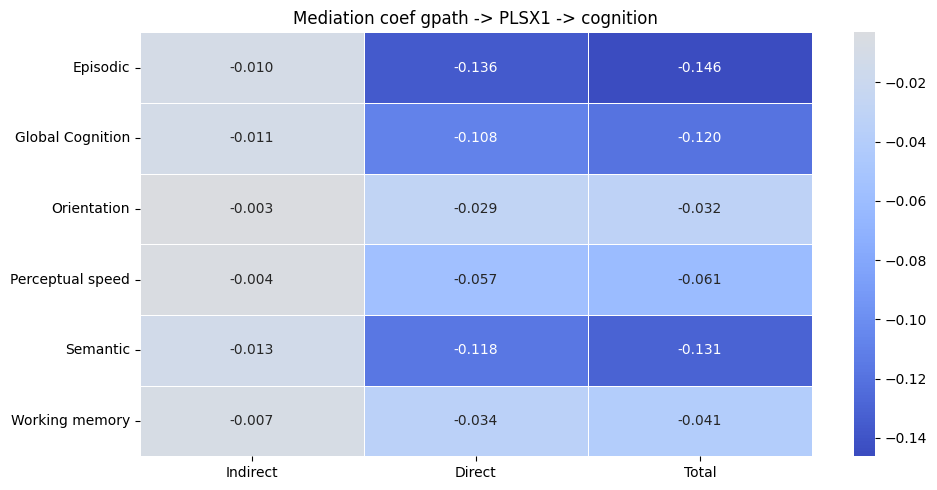

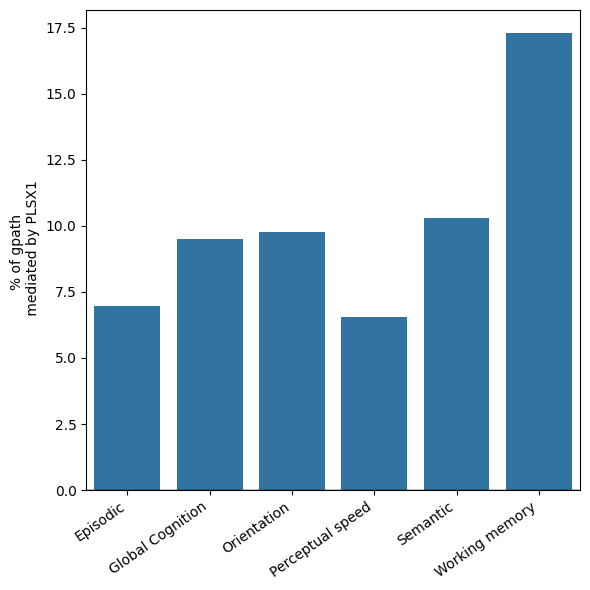

,path,coef,se,pval,CI2.5,CI97.5,sig,Outcome,Cognition_smpl
4,Indirect,-0.010180,0.006168,0.0840,-0.023473,0.000828,No,cognep_demog_slope,Episodic
9,Indirect,-0.011367,0.006331,0.0572,-0.025075,-0.000099,No,cogng_demog_slope,Global Cognition
14,Indirect,-0.003100,0.003283,0.3204,-0.010204,0.002952,No,cognpo_demog_slope,Orientation
19,Indirect,-0.003987,0.004970,0.3980,-0.014161,0.005576,No,cognps_demog_slope,Perceptual speed
24,Indirect,-0.013482,0.007813,0.0764,-0.030378,0.000684,No,cognse_demog_slope,Semantic
29,Indirect,-0.007016,0.004025,0.0672,-0.015511,0.000438,No,cognwo_demog_slope,Working memory


In [13]:
all_mediation_results, indirect_df, direct_df, total_df = run_mediation(df_cog, x="gpath", m="C1", y_list=cog_demog, covar=["AgeDeath","sex"])

title = "Mediation coef gpath -> PLSX1 -> cognition"
mediation_heatmap(all_mediation_results, title, save=True, filename="gpath_PLSX1_cognition")

ylab = "% of gpath \n mediated by PLSX1"
propdf = perc_mediated(total_df, indirect_df, ylab, save=True, filename="gpath_PLSX1_cognition_percentmediated")
indirect_df

## PLSX1 -> Gpath -> Cognition

In [15]:
med = pg.mediation_analysis(data=df_cog, x='C1', m='gpath', y='cogng_demog_slope', covar=["AgeDeath","sex"], n_boot=5000, seed=42)
med

,path,coef,se,pval,CI2.5,CI97.5,sig
0,gpath ~ X,0.046807,0.007610,3.596780e-09,0.031809,0.061804,Yes
1,Y ~ gpath,-0.119636,0.014565,1.821233e-14,-0.148341,-0.090931,Yes
2,Total,-0.008694,0.001948,1.292996e-05,-0.012533,-0.004854,Yes
3,Direct,-0.003626,0.001916,5.967214e-02,-0.007401,0.000149,No
4,Indirect,-0.005068,0.001260,0.000000e+00,-0.007914,-0.002966,Yes


In [16]:
med = pg.mediation_analysis(data=df_cog, x='C1', m='gpath', y='cognep_demog_slope', covar=["AgeDeath","sex"], n_boot=5000, seed=42)
med


,path,coef,se,pval,CI2.5,CI97.5,sig
0,gpath ~ X,0.046485,0.007626,4.857577e-09,0.031456,0.061514,Yes
1,Y ~ gpath,-0.146190,0.014514,7.484862e-20,-0.174795,-0.117585,Yes
2,Total,-0.009585,0.002043,4.755290e-06,-0.013610,-0.005559,Yes
3,Direct,-0.003262,0.001907,8.864514e-02,-0.007022,0.000497,No
4,Indirect,-0.006322,0.001331,0.000000e+00,-0.009164,-0.004036,Yes


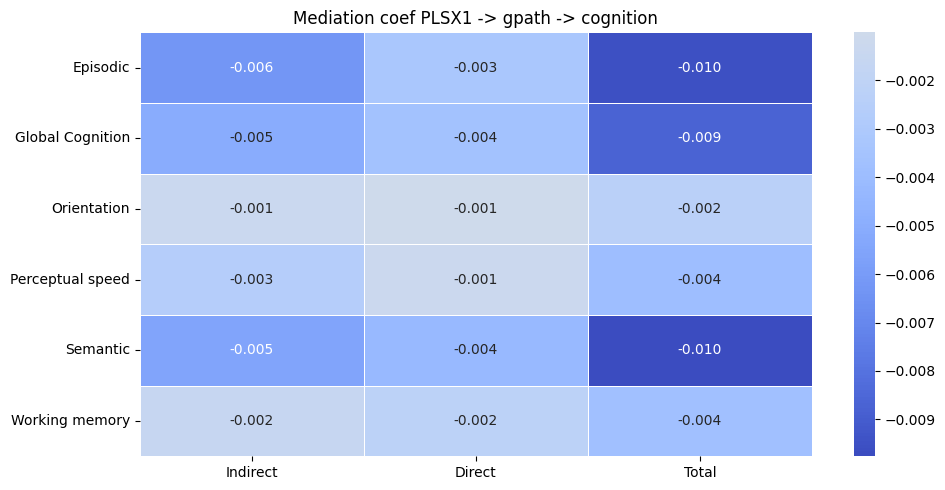

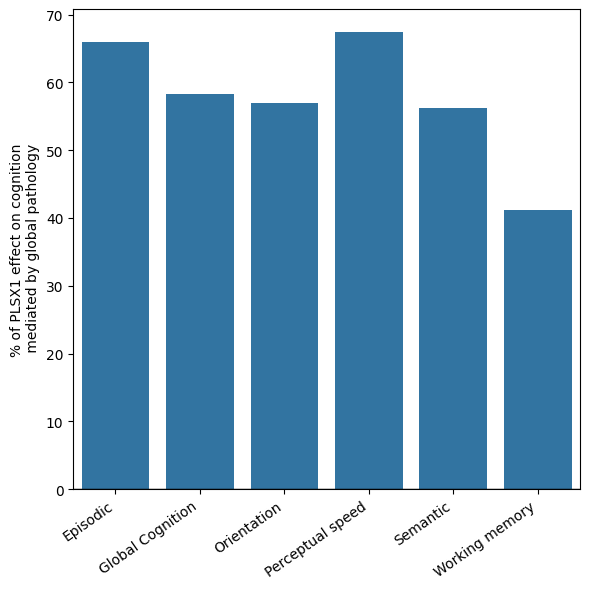

,path,coef,se,pval,CI2.5,CI97.5,sig,Outcome,Cognition_smpl
4,Indirect,-0.006322,0.001331,0.0000,-0.009164,-0.004036,Yes,cognep_demog_slope,Episodic
9,Indirect,-0.005068,0.001260,0.0000,-0.007914,-0.002966,Yes,cogng_demog_slope,Global Cognition
14,Indirect,-0.001333,0.000452,0.0016,-0.002363,-0.000576,Yes,cognpo_demog_slope,Orientation
19,Indirect,-0.002652,0.000730,0.0000,-0.004339,-0.001428,Yes,cognps_demog_slope,Perceptual speed
24,Indirect,-0.005494,0.001553,0.0000,-0.009182,-0.003032,Yes,cognse_demog_slope,Semantic
29,Indirect,-0.001569,0.000568,0.0016,-0.002898,-0.000628,Yes,cognwo_demog_slope,Working memory


In [19]:
allmed_res, indir_df, dir_df, tot_df = run_mediation(df_cog, x="C1", m="gpath", 
                                                     y_list=cog_demog, 
                                                     covar=["AgeDeath","sex"])

title = "Mediation coef PLSX1 -> gpath -> cognition"
mediation_heatmap(allmed_res, title, save=True, filename="PLSX1_gpath_cognition")
ylab = "% of PLSX1 effect on cognition\n mediated by global pathology"
propdf = perc_mediated(tot_df, indir_df, ylab, save=True, filename="PLSX1_gpath_cognition")

indir_df

# Moderation

In [22]:
bins = [0, 0.5, 1, 1.5]
labels = ["low", "mid", "high"]
df_cog["gpath_group"] = pd.cut(df_cog["gpath"], bins=bins, labels=labels, include_lowest=True)

In [23]:
import statsmodels.formula.api as smf

model = smf.ols(
    "cognep_demog_slope ~ C1 * gpath + AgeDeath + sex",
    data=df_cog
).fit()

print(model.summary())

                            OLS Regression Results                            
Dep. Variable:     cognep_demog_slope   R-squared:                       0.360
Model:                            OLS   Adj. R-squared:                  0.345
Method:                 Least Squares   F-statistic:                     24.42
Date:                Wed, 15 Jul 2026   Prob (F-statistic):           1.78e-19
Time:                        18:28:53   Log-Likelihood:                 254.27
No. Observations:                 223   AIC:                            -496.5
Df Residuals:                     217   BIC:                            -476.1
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
Intercept     -0.1652      0.076     -2.178      0.0

In [24]:
med_res = []

for cog in cog_demog:
    model = smf.ols(f'{cog} ~ C1 * gpath + AgeDeath + sex', data=df_cog).fit()

    med_res.append({
        "cognition": cog,
        "n": int(model.nobs),
        "C1_beta": model.params.get("C1"),
        "C1_pval": model.pvalues.get("C1"),
        "gpath_beta": model.params.get("gpath"),
        "gpath_pval": model.pvalues.get("gpath"),
        "C1_gpath_interaction_beta": model.params.get("C1:gpath"),
        "C1_gpath_interaction_pval": model.pvalues.get("C1:gpath"),
        "R2": model.rsquared,
        "adj_R2": model.rsquared_adj
    })

med_res = pd.DataFrame(med_res)    
med_res["interaction_FDR"] = multipletests(med_res["C1_gpath_interaction_pval"],method="fdr_bh")[1]
med_res

,cognition,n,C1_beta,C1_pval,gpath_beta,gpath_pval,C1_gpath_interaction_beta,C1_gpath_interaction_pval,R2,adj_R2,interaction_FDR
0,cognep_demog_slope,223,0.002263,0.377821,-0.123889,1.938738e-13,-0.015154,0.001825,0.360030,0.345285,0.010952
1,cogng_demog_slope,224,0.000930,0.719641,-0.098374,3.297607e-09,-0.012514,0.010573,0.277867,0.261304,0.021146
2,cognpo_demog_slope,218,-0.001400,0.253976,-0.029418,1.230394e-04,0.001096,0.636417,0.119496,0.098729,0.763700
3,cognps_demog_slope,219,-0.001457,0.466734,-0.057365,5.566583e-06,0.000486,0.896100,0.150760,0.130824,0.896100
4,cognse_demog_slope,221,0.001891,0.550444,-0.104504,2.147425e-07,-0.016759,0.004891,0.248183,0.230699,0.014673
5,cognwo_demog_slope,224,-0.000657,0.670925,-0.030093,1.782912e-03,-0.004343,0.135087,0.120870,0.100706,0.202631


In [25]:
moderation_res = []

for cog in cog_demog:
    model = smf.ols(
        f"{cog} ~ C1 * gpath + AgeDeath + sex",
        data=df_cog
    ).fit()

    interaction_term = "C1:gpath"
    interaction_ci = model.conf_int().loc[interaction_term]

    moderation_res.append({
        "cognition": cog,
        "n": int(model.nobs),

        "C1_beta": model.params.get("C1"),
        "C1_t": model.tvalues.get("C1"),
        "C1_pval": model.pvalues.get("C1"),

        "gpath_beta": model.params.get("gpath"),
        "gpath_t": model.tvalues.get("gpath"),
        "gpath_pval": model.pvalues.get("gpath"),

        "C1_gpath_interaction_beta": model.params.get(interaction_term),
        "C1_gpath_interaction_CI_low": interaction_ci.iloc[0],
        "C1_gpath_interaction_CI_high": interaction_ci.iloc[1],
        "C1_gpath_interaction_t": model.tvalues.get(interaction_term),
        "C1_gpath_interaction_pval": model.pvalues.get(interaction_term),

        "R2": model.rsquared,
        "adj_R2": model.rsquared_adj
    })

moderation_res = pd.DataFrame(moderation_res)

moderation_res["interaction_FDR"] = multipletests(
    moderation_res["C1_gpath_interaction_pval"],
    method="fdr_bh"
)[1]

moderation_res

,cognition,n,C1_beta,C1_t,C1_pval,gpath_beta,gpath_t,gpath_pval,C1_gpath_interaction_beta,C1_gpath_interaction_CI_low,C1_gpath_interaction_CI_high,C1_gpath_interaction_t,C1_gpath_interaction_pval,R2,adj_R2,interaction_FDR
0,cognep_demog_slope,223,0.002263,0.883728,0.377821,-0.123889,-7.845634,1.938738e-13,-0.015154,-0.024618,-0.005691,-3.156206,0.001825,0.360030,0.345285,0.010952
1,cogng_demog_slope,224,0.000930,0.359404,0.719641,-0.098374,-6.169194,3.297607e-09,-0.012514,-0.022079,-0.002950,-2.578772,0.010573,0.277867,0.261304,0.021146
2,cognpo_demog_slope,218,-0.001400,-1.143850,0.253976,-0.029418,-3.912485,1.230394e-04,0.001096,-0.003466,0.005657,0.473397,0.636417,0.119496,0.098729,0.763700
3,cognps_demog_slope,219,-0.001457,-0.729112,0.466734,-0.057365,-4.660151,5.566583e-06,0.000486,-0.006846,0.007819,0.130746,0.896100,0.150760,0.130824,0.896100
4,cognse_demog_slope,221,0.001891,0.598038,0.550444,-0.104504,-5.359155,2.147425e-07,-0.016759,-0.028376,-0.005143,-2.843589,0.004891,0.248183,0.230699,0.014673
5,cognwo_demog_slope,224,-0.000657,-0.425455,0.670925,-0.030093,-3.163189,1.782912e-03,-0.004343,-0.010049,0.001364,-1.499899,0.135087,0.120870,0.100706,0.202631


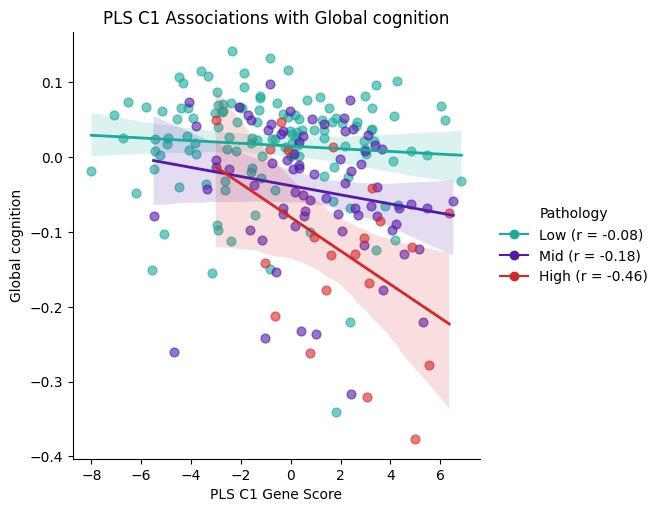

In [26]:
from matplotlib.lines import Line2D

cognition = 'cogng_demog_slope'
label = 'Global cognition'

palette = {
    "low": "#1AAB9B",
    "mid": "#521AAB",
    "high": "#D62728"
    }

# correlations
corrs = {}
for grp in ["low", "mid", "high"]:
    sub = df_cog[df_cog["gpath_group"] == grp]
    r = sub[["C1", cognition]].dropna().corr().iloc[0, 1]
    corrs[grp] = r

# plot
g = sns.lmplot(
    data=df_cog,
    x="C1",
    y=cognition,
    hue="gpath_group",
    palette=palette,
    height=5,
    aspect=1,
    scatter_kws={"alpha":0.6, "s":40},
    line_kws={"linewidth":2},
    legend=False)

ax = g.ax

handles = [
    Line2D(
        [0], [0],
        marker='o',
        color=palette[grp],
        linestyle='-',
        markersize=6,
        label=f"{grp.capitalize()} (r = {corrs[grp]:.2f})")
    for grp in ["low", "mid", "high"]]

ax.legend(
    handles=handles,
    title="Pathology",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False)

plt.xlabel("PLS C1 Gene Score")
plt.ylabel(label)
plt.title(f"PLS C1 Associations with {label}")
plt.savefig(os.path.join(fig_dir, "moder_C1gpath_global.pdf"), dpi=300)

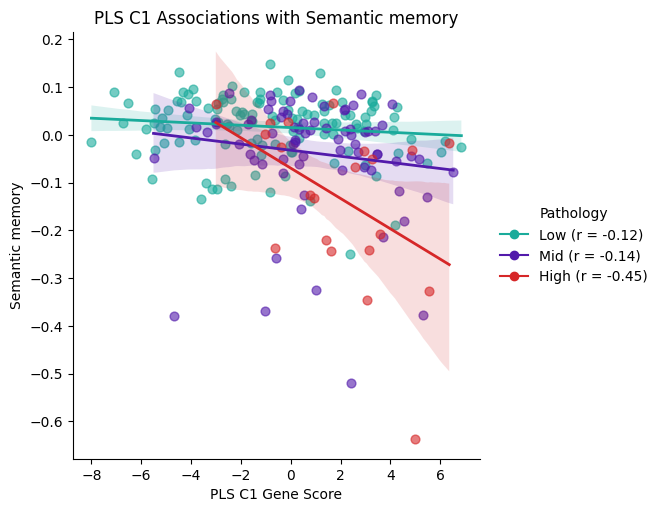

In [27]:
from matplotlib.lines import Line2D

cognition = 'cognse_demog_slope'
label = 'Semantic memory'

palette = {
    "low": "#1AAB9B",
    "mid": "#521AAB",
    "high": "#D62728"
    }

# correlations
corrs = {}
for grp in ["low", "mid", "high"]:
    sub = df_cog[df_cog["gpath_group"] == grp]
    r = sub[["C1", cognition]].dropna().corr().iloc[0, 1]
    corrs[grp] = r

# plot
g = sns.lmplot(
    data=df_cog,
    x="C1",
    y=cognition,
    hue="gpath_group",
    palette=palette,
    height=5,
    aspect=1,
    scatter_kws={"alpha":0.6, "s":40},
    line_kws={"linewidth":2},
    legend=False)

ax = g.ax

handles = [
    Line2D(
        [0], [0],
        marker='o',
        color=palette[grp],
        linestyle='-',
        markersize=6,
        label=f"{grp.capitalize()} (r = {corrs[grp]:.2f})")
    for grp in ["low", "mid", "high"]]

ax.legend(
    handles=handles,
    title="Pathology",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False)

plt.xlabel("PLS C1 Gene Score")
plt.ylabel(label)
plt.title(f"PLS C1 Associations with {label}")
plt.savefig(os.path.join(fig_dir, "moder_C1gpath_semantic.pdf"), dpi=300)

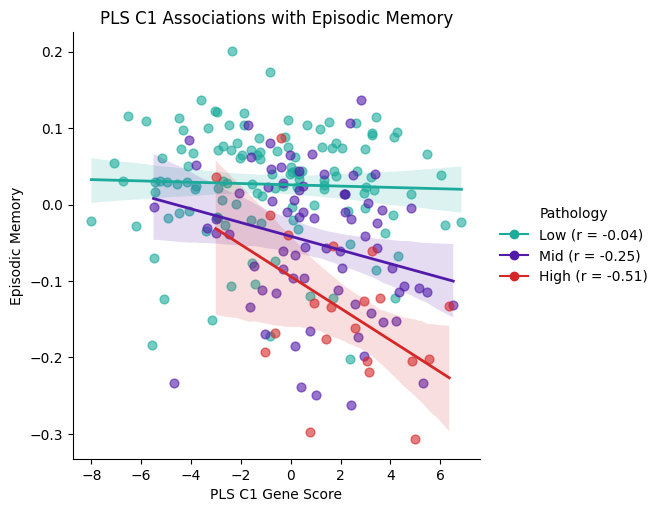

In [28]:
from matplotlib.lines import Line2D

cognition = 'cognep_demog_slope'
label = 'Episodic Memory'

palette = {
    "low": "#1AAB9B",
    "mid": "#521AAB",
    "high": "#D62728"
    }

# correlations
corrs = {}
for grp in ["low", "mid", "high"]:
    sub = df_cog[df_cog["gpath_group"] == grp]
    r = sub[["C1", cognition]].dropna().corr().iloc[0, 1]
    corrs[grp] = r

# plot
g = sns.lmplot(
    data=df_cog,
    x="C1",
    y=cognition,
    hue="gpath_group",
    palette=palette,
    height=5,
    aspect=1,
    scatter_kws={"alpha":0.6, "s":40},
    line_kws={"linewidth":2},
    legend=False)

ax = g.ax

handles = [
    Line2D(
        [0], [0],
        marker='o',
        color=palette[grp],
        linestyle='-',
        markersize=6,
        label=f"{grp.capitalize()} (r = {corrs[grp]:.2f})")
    for grp in ["low", "mid", "high"]]

ax.legend(
    handles=handles,
    title="Pathology",
    bbox_to_anchor=(1.02, 0.5),
    loc="center left",
    frameon=False)

plt.xlabel("PLS C1 Gene Score")
plt.ylabel(label)
plt.title(f"PLS C1 Associations with {label}")
plt.savefig(os.path.join(fig_dir, "moder_C1gpath_Episodic.pdf"), dpi=300)

<Figure size 600x500 with 0 Axes>

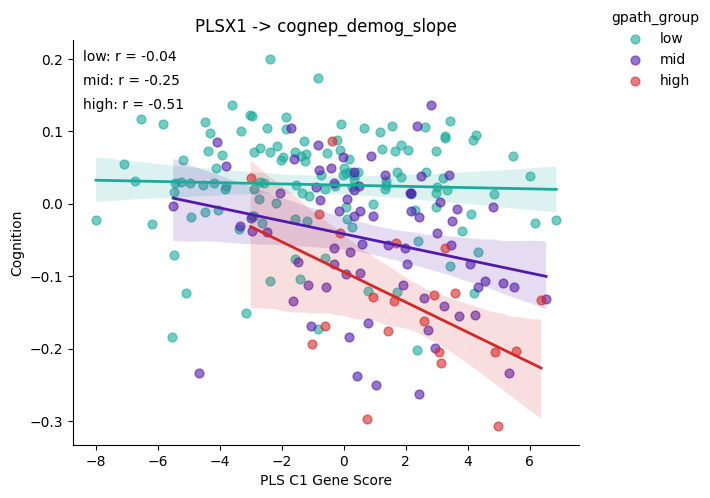

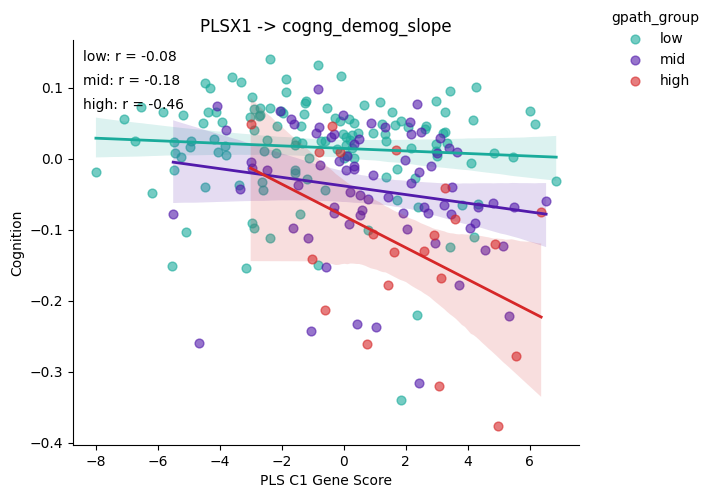

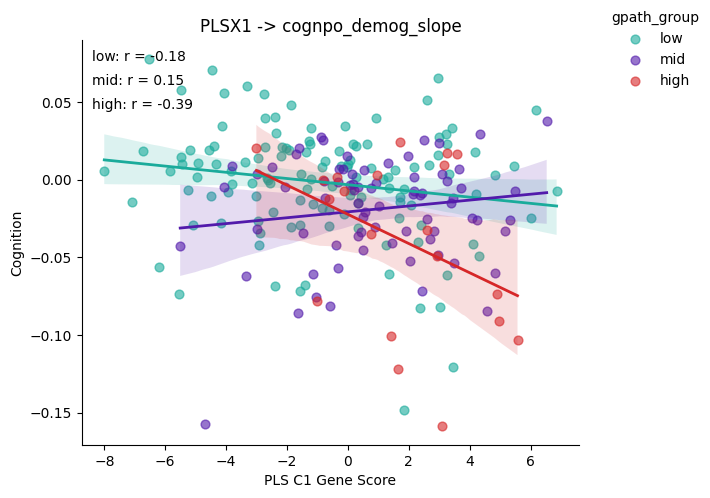

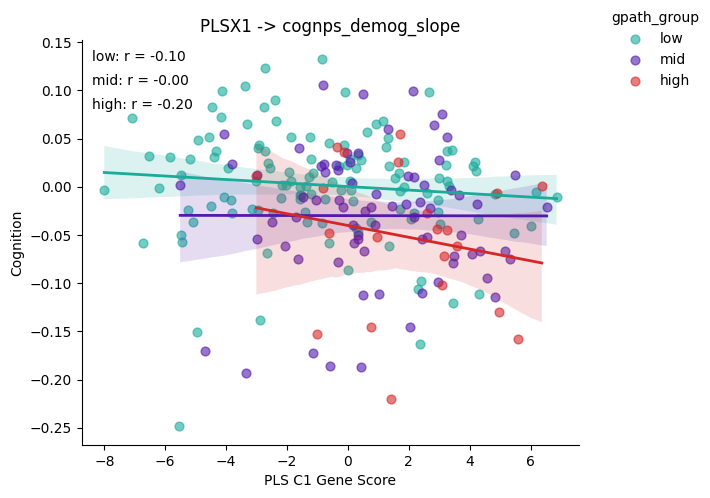

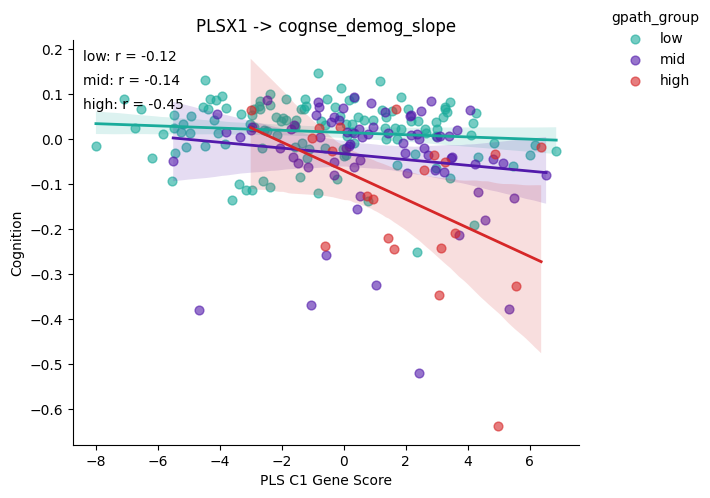

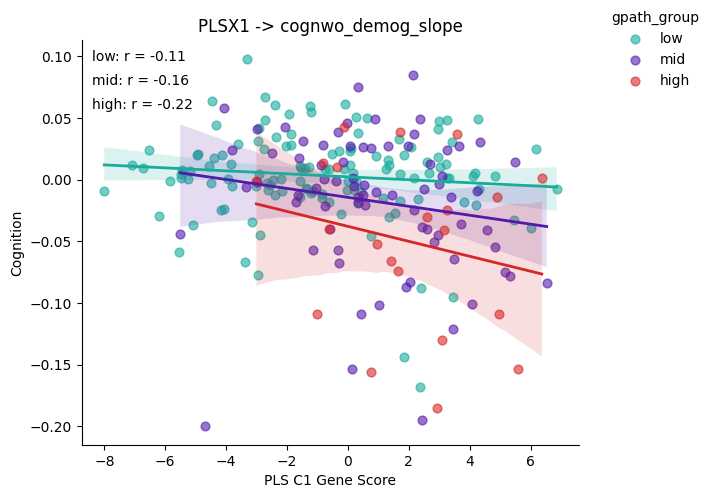

In [29]:
plt.figure(figsize=(6,5))
for cognition in cog_demog:
    g =sns.lmplot(
        data=df_cog,
        x="C1",
        y=cognition,
        hue="gpath_group",
        palette={
            "low": "#1AAB9B",
            "mid": "#521AAB",
            "high": "#D62728"
        },
        height=5,
        aspect=1,
        scatter_kws={"alpha":0.6, "s":40},
        line_kws={"linewidth":2}
    )
    ax = g.ax
    y_text = 0.95
    for grp in ["low", "mid", "high"]:
        sub = df_cog[df_cog["gpath_group"] == grp]
        slope = sub[[ "C1", cognition ]].dropna().corr().iloc[0, 1]   # quick number
        ax.text(0.02, y_text, f"{grp}: r = {slope:.2f}", transform=ax.transAxes)
        y_text -= 0.06

    g._legend.set_bbox_to_anchor((1.0, 1))
    g._legend.set_loc("upper left")

    plt.xlabel("PLS C1 Gene Score")
    plt.ylabel("Cognition")
    plt.title(f"PLSX1 -> {cognition}")

    plt.tight_layout()
    plt.show()